In [1]:
!pip install -q datasets

In [2]:
!pip -q install datasets scikit-learn pandas numpy matplotlib seaborn gradio joblib

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np

dataset = load_dataset(
    "Nandhini3737/standardized-food-nutrition-dataset",
    split="train"
)

df = dataset.to_pandas()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

README.md:   0%|          | 0.00/7.09k [00:00<?, ?B/s]

daily_food_nutrition.csv:   0%|          | 0.00/42.9k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/587 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset shape: (587, 12)


,Food_Item,Category,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Sugars (g),Sodium (mg),Cholesterol (mg),Meal_Type,Water_Intake (ml)
0,Scrambled Eggs (2 large),Protein/Dairy,180,12.0,2.0,14.0,0.0,1.0,180,370,Breakfast,250
1,Whole Wheat Toast (1 slice),Grain,80,4.0,14.0,1.0,2.0,2.0,140,0,Breakfast,0
2,Coffee (black),Beverage,5,0.3,0.0,0.1,0.0,0.0,5,0,Breakfast,0
3,Banana,Fruit,105,1.3,27.0,0.4,3.1,14.0,1,0,Breakfast,0
4,Grilled Chicken Salad,Meal/Protein,350,30.0,10.0,20.0,5.0,4.0,400,80,Lunch,500



Column names:
['Food_Item', 'Category', 'Calories (kcal)', 'Protein (g)', 'Carbohydrates (g)', 'Fat (g)', 'Fiber (g)', 'Sugars (g)', 'Sodium (mg)', 'Cholesterol (mg)', 'Meal_Type', 'Water_Intake (ml)']


In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumber of food categories:")
print(df["Category"].nunique())

print("\nMost common categories:")
print(df["Category"].value_counts().head(15))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 587 entries, 0 to 586
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Food_Item          587 non-null    object 
 1   Category           587 non-null    object 
 2   Calories (kcal)    587 non-null    int64  
 3   Protein (g)        587 non-null    float64
 4   Carbohydrates (g)  587 non-null    float64
 5   Fat (g)            587 non-null    float64
 6   Fiber (g)          587 non-null    float64
 7   Sugars (g)         587 non-null    float64
 8   Sodium (mg)        587 non-null    int64  
 9   Cholesterol (mg)   587 non-null    int64  
 10  Meal_Type          587 non-null    object 
 11  Water_Intake (ml)  587 non-null    int64  
dtypes: float64(5), int64(4), object(3)
memory usage: 55.2+ KB

Missing values in each column:
Food_Item            0
Category             0
Calories (kcal)      0
Protein (g)          0
Carbohydrates (

In [5]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Our target is the existing food category
df = df.dropna(subset=["Category"]).copy()

# Keep only numeric nutrition columns as model inputs
nutrition_columns = [
    "Calories (kcal)",
    "Protein (g)",
    "Carbohydrates (g)",
    "Fat (g)",
    "Fiber (g)",
    "Sugars (g)",
    "Sodium (mg)",
    "Cholesterol (mg)",
    "Water_Intake (ml)"
]

# Keep only columns that actually exist in the dataset
nutrition_columns = [
    col for col in nutrition_columns if col in df.columns
]

# Convert inputs to numeric and handle missing values
for col in nutrition_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[nutrition_columns] = df[nutrition_columns].fillna(
    df[nutrition_columns].median()
)

# Remove categories that have too few examples for a reliable split
category_counts = df["Category"].value_counts()
valid_categories = category_counts[category_counts >= 5].index

df = df[df["Category"].isin(valid_categories)].copy()

print("Cleaned dataset shape:", df.shape)
print("\nCategories used:")
print(df["Category"].value_counts())

Cleaned dataset shape: (544, 12)

Categories used:
Category
Condiment             113
Vegetable              65
Beverage               50
Grain                  49
Fruit                  31
Meal/Processed         28
Protein/Meat           27
Dessert                26
Dairy                  25
Meal/Meat              19
Snack/Processed        15
Meal/Pasta             14
Nut                    13
Meal/Vegetarian        10
Legume                  9
Protein/Fish            8
Meal/Vegetable          8
Grain/Processed         7
Protein/Vegetarian      6
Meal/Seafood            6
Condiment/Dairy         5
Protein/Seafood         5
Meal/Grain              5
Name: count, dtype: int64


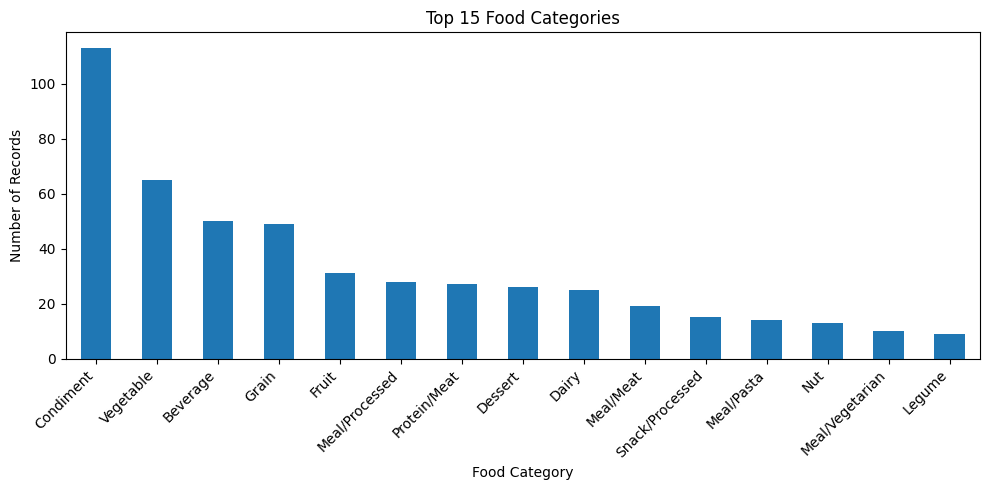

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
df["Category"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 Food Categories")
plt.xlabel("Food Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

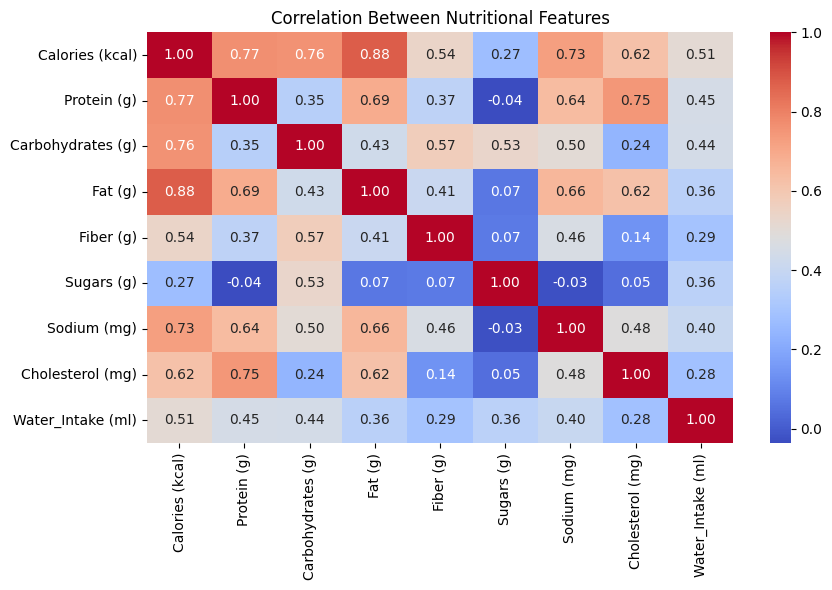

In [7]:
plt.figure(figsize=(9, 6))

correlation = df[nutrition_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Nutritional Features")
plt.tight_layout()
plt.show()

In [8]:
X = df[nutrition_columns].copy()
y = df["Category"].astype(str).copy()

print("Features:", X.columns.tolist())
print("Number of input features:", X.shape[1])
print("Number of target categories:", y.nunique())

Features: ['Calories (kcal)', 'Protein (g)', 'Carbohydrates (g)', 'Fat (g)', 'Fiber (g)', 'Sugars (g)', 'Sodium (mg)', 'Cholesterol (mg)', 'Water_Intake (ml)']
Number of input features: 9
Number of target categories: 23


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 435
Testing rows: 109


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf"))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Weighted F1": f1
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    by="Weighted F1",
    ascending=False
)

display(results_df)

,Model,Accuracy,Weighted F1
2,Random Forest,0.669725,0.642540
0,Logistic Regression,0.642202,0.605789
1,SVM,0.596330,0.567265


Selected baseline: Random Forest

Classification Report:

                    precision    recall  f1-score   support

          Beverage       0.82      0.90      0.86        10
         Condiment       0.66      0.83      0.73        23
   Condiment/Dairy       0.00      0.00      0.00         1
             Dairy       0.83      1.00      0.91         5
           Dessert       0.75      0.60      0.67         5
             Fruit       0.80      0.67      0.73         6
             Grain       0.57      0.80      0.67        10
   Grain/Processed       0.00      0.00      0.00         1
            Legume       1.00      0.50      0.67         2
        Meal/Grain       0.00      0.00      0.00         1
         Meal/Meat       0.25      0.25      0.25         4
        Meal/Pasta       0.50      0.33      0.40         3
    Meal/Processed       0.57      0.67      0.62         6
      Meal/Seafood       0.00      0.00      0.00         1
    Meal/Vegetable       0.50      0.50  

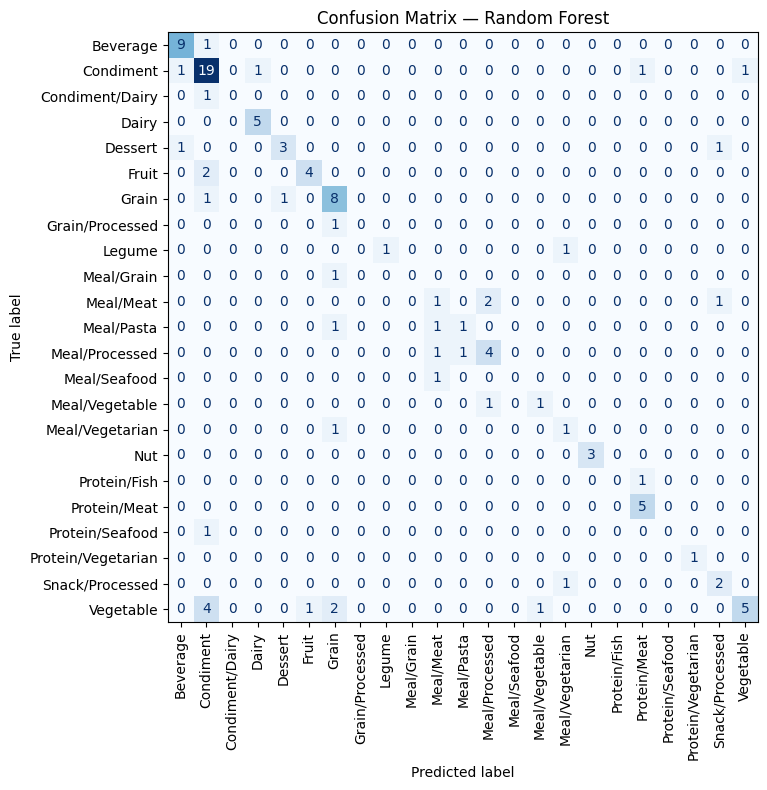

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

y_pred = best_model.predict(X_test)

print("Selected baseline:", best_name)
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", class_weight="balanced"))
])

param_grid = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.1, 0.01]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean cross-validation weighted F1:",
      round(grid_search.best_score_, 4))

Fitting 3 folds for each of 9 candidates, totalling 27 fits
Best parameters: {'model__C': 10, 'model__gamma': 0.1}
Best mean cross-validation weighted F1: 0.5469


In [13]:
tuned_svm = grid_search.best_estimator_

tuned_predictions = tuned_svm.predict(X_test)

print("Tuned SVM test accuracy:",
      round(accuracy_score(y_test, tuned_predictions), 4))

print("Tuned SVM test weighted F1:",
      round(f1_score(
          y_test,
          tuned_predictions,
          average="weighted",
          zero_division=0
      ), 4))

print("\nTuned SVM classification report:\n")
print(classification_report(
    y_test,
    tuned_predictions,
    zero_division=0
))

Tuned SVM test accuracy: 0.6055
Tuned SVM test weighted F1: 0.5945

Tuned SVM classification report:

                    precision    recall  f1-score   support

          Beverage       1.00      0.90      0.95        10
         Condiment       0.67      0.78      0.72        23
   Condiment/Dairy       0.20      1.00      0.33         1
             Dairy       0.60      0.60      0.60         5
           Dessert       0.80      0.80      0.80         5
             Fruit       0.57      0.67      0.62         6
             Grain       1.00      0.50      0.67        10
   Grain/Processed       0.20      1.00      0.33         1
            Legume       0.33      0.50      0.40         2
        Meal/Grain       0.50      1.00      0.67         1
         Meal/Meat       0.33      0.25      0.29         4
        Meal/Pasta       0.50      0.33      0.40         3
    Meal/Processed       0.50      0.67      0.57         6
      Meal/Seafood       0.00      0.00      0.00        

In [14]:
import joblib

final_model = tuned_svm

joblib.dump(
    {
        "model": final_model,
        "features": nutrition_columns,
        "categories": sorted(y.unique().tolist())
    },
    "nutriscore_model.joblib"
)

print("Model saved as nutriscore_model.joblib")

Model saved as nutriscore_model.joblib


In [18]:
import gradio as gr
import pandas as pd
import joblib

saved = joblib.load("nutriscore_model.joblib")
final_model = saved["model"]
feature_names = saved["features"]

def predict_food_category(
    calories,
    protein,
    carbohydrates,
    fat,
    fiber,
    sugars,
    sodium,
    cholesterol,
    water
):
    values = {
        "Calories (kcal)": calories,
        "Protein (g)": protein,
        "Carbohydrates (g)": carbohydrates,
        "Fat (g)": fat,
        "Fiber (g)": fiber,
        "Sugars (g)": sugars,
        "Sodium (mg)": sodium,
        "Cholesterol (mg)": cholesterol,
        "Water_Intake (ml)": water
    }

    # Match the feature columns used during training
    input_data = pd.DataFrame([{
        feature: values[feature] for feature in feature_names
    }])

    prediction = final_model.predict(input_data)[0]

    summary = "\n".join(
        f"{name}: {value}" for name, value in values.items()
    )

    return str(prediction), (
        f"Entered nutrition profile:\n{summary}\n\n"
        "Note: this is a food-category prediction, not a medical "
        "or official health rating."
    )

demo = gr.Interface(
    fn=predict_food_category,
    inputs=[
        gr.Number(label="Calories (kcal)", value=150, minimum=0),
        gr.Number(label="Protein (g)", value=5, minimum=0),
        gr.Number(label="Carbohydrates (g)", value=20, minimum=0),
        gr.Number(label="Fat (g)", value=4, minimum=0),
        gr.Number(label="Fiber (g)", value=3, minimum=0),
        gr.Number(label="Sugars (g)", value=5, minimum=0),
        gr.Number(label="Sodium (mg)", value=100, minimum=0),
        gr.Number(label="Cholesterol (mg)", value=0, minimum=0),
        gr.Number(label="Water intake (ml)", value=0, minimum=0)
    ],
    outputs=[
        gr.Textbox(label="Predicted Food Category"),
        gr.Textbox(label="Nutrition Profile", lines=12)
    ],
    title="NutriScore AI",
    description=(
        "Explore nutrition values and predict a food category "
        "using a machine-learning model trained on food data."
    )
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://30f9e8e8268a2dfbb2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://30f9e8e8268a2dfbb2.gradio.live
